In [1]:
# Install:
# pip install -U langgraph

from typing import TypedDict
from langgraph.graph import StateGraph, START, END


# -------------------------------------------------
# Shared state passed between agents
# -------------------------------------------------
class AgentState(TypedDict):
    destination: str
    route: str
    traffic_status: str
    weather_status: str
    final_decision: str
    retry_count: int


# -------------------------------------------------
# Agent 1: Planner Agent
# -------------------------------------------------
def planner_agent(state: AgentState):
    print("\n===== PLANNER AGENT =====")

    if state["retry_count"] == 0:
        route = "Route A"
    else:
        route = "Route B"

    print(f"Destination: {state['destination']}")
    print(f"Selected candidate route: {route}")

    return {
        **state,
        "route": route
    }


# -------------------------------------------------
# Agent 2: Traffic Agent
# -------------------------------------------------
def traffic_agent(state: AgentState):
    print("\n===== TRAFFIC AGENT =====")
    print(f"Received route from Planner Agent: {state['route']}")

    if state["route"] == "Route A":
        traffic = "Heavy traffic"
    else:
        traffic = "Light traffic"

    print("Traffic result:", traffic)

    return {
        **state,
        "traffic_status": traffic
    }


# -------------------------------------------------
# Agent 3: Weather Agent
# -------------------------------------------------
def weather_agent(state: AgentState):
    print("\n===== WEATHER AGENT =====")
    print("Checking weather for route...")

    if state["route"] == "Route A":
        weather = "Heavy rain"
    else:
        weather = "Clear"

    print("Weather result:", weather)

    return {
        **state,
        "weather_status": weather
    }


# -------------------------------------------------
# Agent 4: Decision Agent
# -------------------------------------------------
def decision_agent(state: AgentState):
    print("\n===== DECISION AGENT =====")

    print("Traffic:", state["traffic_status"])
    print("Weather:", state["weather_status"])

    if (
        state["traffic_status"] == "Light traffic"
        and state["weather_status"] == "Clear"
    ):
        decision = f"APPROVED: Use {state['route']}"

    else:
        decision = "REPLAN_REQUIRED"

    print("Decision:", decision)

    return {
        **state,
        "final_decision": decision
    }


# -------------------------------------------------
# Conditional routing function
# -------------------------------------------------
def check_decision(state: AgentState):

    if (
        state["final_decision"] == "REPLAN_REQUIRED"
        and state["retry_count"] < 1
    ):
        print("\nDecision Agent -> Planner Agent")
        print("Request: Find another route")

        return "replan"

    return "finish"


# -------------------------------------------------
# Retry/update agent
# -------------------------------------------------
def retry_agent(state: AgentState):
    print("\n===== FEEDBACK MESSAGE =====")
    print("Decision Agent rejected current route.")
    print("Sending feedback to Planner Agent.")

    return {
        **state,
        "retry_count": state["retry_count"] + 1
    }


# -------------------------------------------------
# Build LangGraph workflow
# -------------------------------------------------
workflow = StateGraph(AgentState)

workflow.add_node("planner", planner_agent)
workflow.add_node("traffic", traffic_agent)
workflow.add_node("weather", weather_agent)
workflow.add_node("decision", decision_agent)
workflow.add_node("retry", retry_agent)


# -------------------------------------------------
# Define communication flow
# -------------------------------------------------
workflow.add_edge(START, "planner")

workflow.add_edge("planner", "traffic")

workflow.add_edge("traffic", "weather")

workflow.add_edge("weather", "decision")


# Conditional communication
workflow.add_conditional_edges(
    "decision",
    check_decision,
    {
        "replan": "retry",
        "finish": END
    }
)

workflow.add_edge("retry", "planner")


# Compile
app = workflow.compile()


# -------------------------------------------------
# Run workflow
# -------------------------------------------------
result = app.invoke({
    "destination": "Airport",
    "route": "",
    "traffic_status": "",
    "weather_status": "",
    "final_decision": "",
    "retry_count": 0
})


# -------------------------------------------------
# Final output
# -------------------------------------------------
print("\n==============================")
print("FINAL RESULT")
print("==============================")

print("Destination:", result["destination"])
print("Selected Route:", result["route"])
print("Traffic:", result["traffic_status"])
print("Weather:", result["weather_status"])
print("Decision:", result["final_decision"])


===== PLANNER AGENT =====
Destination: Airport
Selected candidate route: Route A

===== TRAFFIC AGENT =====
Received route from Planner Agent: Route A
Traffic result: Heavy traffic

===== WEATHER AGENT =====
Checking weather for route...
Weather result: Heavy rain

===== DECISION AGENT =====
Traffic: Heavy traffic
Weather: Heavy rain
Decision: REPLAN_REQUIRED

Decision Agent -> Planner Agent
Request: Find another route

===== FEEDBACK MESSAGE =====
Decision Agent rejected current route.
Sending feedback to Planner Agent.

===== PLANNER AGENT =====
Destination: Airport
Selected candidate route: Route B

===== TRAFFIC AGENT =====
Received route from Planner Agent: Route B
Traffic result: Light traffic

===== WEATHER AGENT =====
Checking weather for route...
Weather result: Clear

===== DECISION AGENT =====
Traffic: Light traffic
Weather: Clear
Decision: APPROVED: Use Route B

FINAL RESULT
Destination: Airport
Selected Route: Route B
Traffic: Light traffic
Weather: Clear
Decision: APPROV

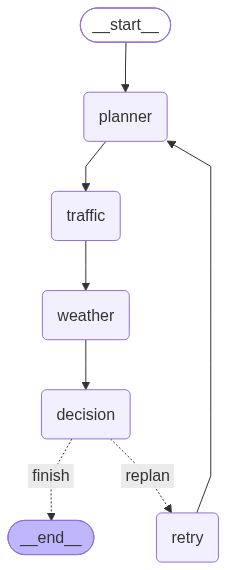

In [3]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))